In [38]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report,
    roc_curve
)

In [39]:
X_train = pd.read_csv("../data/X_train.csv")
X_test = pd.read_csv("../data/X_test.csv")

y_train = pd.read_csv("../data/y_train.csv").squeeze()
y_test = pd.read_csv("../data/y_test.csv").squeeze()

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (237, 13)
X_test : (60, 13)
y_train: (237,)
y_test : (60,)


In [40]:
print("Features:")
print(list(X_train.columns))

Features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [41]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB()
}

print("Models created successfully.")

Models created successfully.


In [42]:
results = []
confusion_matrices = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Train
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Probability
    y_prob = model.predict_proba(X_test)[:, 1]

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    confusion_matrices[name] = cm

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"ROC-AUC  : {roc_auc:.4f}")


Training Logistic Regression...
Accuracy : 0.8333
Precision: 0.8462
Recall   : 0.7857
F1-Score : 0.8148
ROC-AUC  : 0.9498

Training Decision Tree...
Accuracy : 0.6833
Precision: 0.6800
Recall   : 0.6071
F1-Score : 0.6415
ROC-AUC  : 0.6786

Training Random Forest...
Accuracy : 0.8667
Precision: 0.8846
Recall   : 0.8214
F1-Score : 0.8519
ROC-AUC  : 0.9464

Training SVM...
Accuracy : 0.8500
Precision: 0.8800
Recall   : 0.7857
F1-Score : 0.8302
ROC-AUC  : 0.9542

Training KNN...
Accuracy : 0.8833
Precision: 0.9200
Recall   : 0.8214
F1-Score : 0.8679
ROC-AUC  : 0.9492

Training Naive Bayes...
Accuracy : 0.8833
Precision: 0.8889
Recall   : 0.8571
F1-Score : 0.8727
ROC-AUC  : 0.9375


c:\Users\gaura\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [43]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Recall",
    ascending=False
).reset_index(drop=True)

print(results_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
        Naive Bayes  0.883333   0.888889 0.857143  0.872727 0.937500
      Random Forest  0.866667   0.884615 0.821429  0.851852 0.946429
                KNN  0.883333   0.920000 0.821429  0.867925 0.949219
Logistic Regression  0.833333   0.846154 0.785714  0.814815 0.949777
                SVM  0.850000   0.880000 0.785714  0.830189 0.954241
      Decision Tree  0.683333   0.680000 0.607143  0.641509 0.678571


In [44]:
best_model_name = results_df.loc[0, "Model"]

print("Best Model Based on Recall:", best_model_name)
print("Best Recall:", results_df.loc[0, "Recall"])

Best Model Based on Recall: Naive Bayes
Best Recall: 0.8571428571428571


In [45]:
best_model = models[best_model_name]

best_model.fit(X_train, y_train)

print("Best model trained successfully.")

Best model trained successfully.


In [46]:
os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/best_model.pkl"
)

print("Best model saved successfully.")
print("../models/best_model.pkl")

Best model saved successfully.
../models/best_model.pkl


In [47]:
y_pred_best = best_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_best,
    target_names=["No Disease", "Disease"]
))

              precision    recall  f1-score   support

  No Disease       0.88      0.91      0.89        32
     Disease       0.89      0.86      0.87        28

    accuracy                           0.88        60
   macro avg       0.88      0.88      0.88        60
weighted avg       0.88      0.88      0.88        60



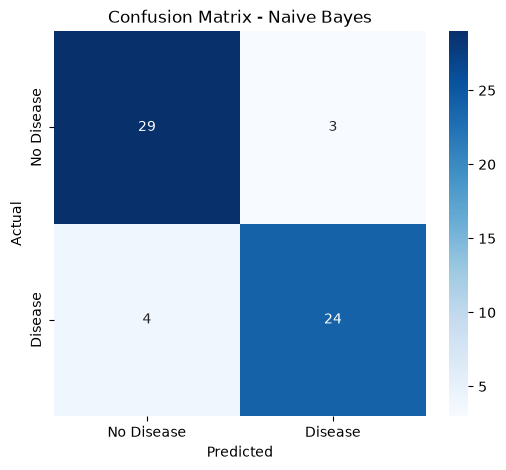

In [48]:
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_model_name}")

plt.show()

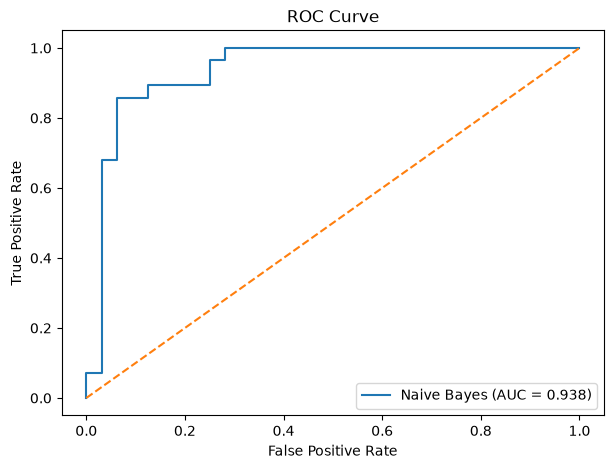

In [49]:
y_prob_best = best_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob_best)

auc_score = roc_auc_score(y_test, y_prob_best)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"{best_model_name} (AUC = {auc_score:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.show()

In [50]:
from lime.lime_tabular import LimeTabularExplainer

In [51]:
scaler = joblib.load("../models/scaler.pkl")
best_model = joblib.load("../models/best_model.pkl")

print("Scaler loaded.")
print("Best model loaded.")

Scaler loaded.
Best model loaded.


In [52]:
explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["No Disease", "Disease"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer created.")

LIME explainer created.


In [53]:
sample_index = 0

sample = X_test.iloc[sample_index].values

prediction = best_model.predict(
    sample.reshape(1, -1)
)[0]

probabilities = best_model.predict_proba(
    sample.reshape(1, -1)
)[0]

print("Prediction:", prediction)
print("Probability of No Disease:", probabilities[0])
print("Probability of Disease:", probabilities[1])

Prediction: 0
Probability of No Disease: 0.9999092235879606
Probability of Disease: 9.077641203777955e-05


c:\Users\gaura\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(
c:\Users\gaura\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


In [54]:
explanation = explainer.explain_instance(
    sample,
    best_model.predict_proba,
    num_features=13
)

print("LIME Explanation:")
print(explanation.as_list())

c:\Users\gaura\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


LIME Explanation:
[('exang <= -0.73', -0.20698943184208296), ('cp <= -0.19', -0.20603991776851502), ('ca <= -0.74', -0.1587379495767434), ('thal <= -0.93', -0.1496662197908206), ('thalach > 0.72', -0.13449960147383083), ('age <= -0.75', -0.11631610975678625), ('oldpeak <= -0.90', -0.09291768873896838), ('slope <= -0.95', -0.07115861000784998), ('trestbps <= -0.69', -0.04922553771247563), ('restecg <= -0.99', -0.031896206284811345), ('-1.44 < sex <= 0.69', 0.0266720187354011), ('chol <= -0.71', -0.019359446624767136), ('fbs <= -0.45', -0.010239269318305808)]


In [58]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Recall",
    ascending=False
).reset_index(drop=True)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
0          Naive Bayes  0.883333   0.888889  0.857143  0.872727  0.937500
1        Random Forest  0.866667   0.884615  0.821429  0.851852  0.946429
2                  KNN  0.883333   0.920000  0.821429  0.867925  0.949219
3  Logistic Regression  0.833333   0.846154  0.785714  0.814815  0.949777
4                  SVM  0.850000   0.880000  0.785714  0.830189  0.954241
5        Decision Tree  0.683333   0.680000  0.607143  0.641509  0.678571


In [59]:
best_model_name = results_df.loc[0, "Model"]

print("Best model:", best_model_name)
print("Best Recall:", results_df.loc[0, "Recall"])

Best model: Naive Bayes
Best Recall: 0.8571428571428571


In [60]:
best_model = models[best_model_name]

best_model.fit(X_train, y_train)

joblib.dump(
    best_model,
    "../models/best_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


In [55]:
top_factors = []

for feature, weight in explanation.as_list():

    top_factors.append({
        "feature": feature,
        "weight": round(float(weight), 4),
        "direction": "positive" if weight > 0 else "negative"
    })

print(top_factors)

[{'feature': 'exang <= -0.73', 'weight': -0.207, 'direction': 'negative'}, {'feature': 'cp <= -0.19', 'weight': -0.206, 'direction': 'negative'}, {'feature': 'ca <= -0.74', 'weight': -0.1587, 'direction': 'negative'}, {'feature': 'thal <= -0.93', 'weight': -0.1497, 'direction': 'negative'}, {'feature': 'thalach > 0.72', 'weight': -0.1345, 'direction': 'negative'}, {'feature': 'age <= -0.75', 'weight': -0.1163, 'direction': 'negative'}, {'feature': 'oldpeak <= -0.90', 'weight': -0.0929, 'direction': 'negative'}, {'feature': 'slope <= -0.95', 'weight': -0.0712, 'direction': 'negative'}, {'feature': 'trestbps <= -0.69', 'weight': -0.0492, 'direction': 'negative'}, {'feature': 'restecg <= -0.99', 'weight': -0.0319, 'direction': 'negative'}, {'feature': '-1.44 < sex <= 0.69', 'weight': 0.0267, 'direction': 'positive'}, {'feature': 'chol <= -0.71', 'weight': -0.0194, 'direction': 'negative'}, {'feature': 'fbs <= -0.45', 'weight': -0.0102, 'direction': 'negative'}]


In [61]:
best_model = joblib.load("../models/best_model.pkl")

print("Best model loaded successfully!")
print(type(best_model))

Best model loaded successfully!
<class 'sklearn.naive_bayes.GaussianNB'>


In [62]:
scaler = joblib.load("../models/scaler.pkl")
best_model = joblib.load("../models/best_model.pkl")

print("Everything is working!")
print("Scaler:", type(scaler))
print("Model :", type(best_model))

Everything is working!
Scaler: <class 'sklearn.preprocessing._data.StandardScaler'>
Model : <class 'sklearn.naive_bayes.GaussianNB'>
